# Vector spherical harmonics

The complex harmonics of `mielib.vsh` are
$$
\mathbf{M}_{jm} = \nabla \times \left(\mathbf{r}\, z_j(\rho)\, Y_{jm}\right), \qquad
\mathbf{N}_{jm} = \frac{1}{k} \nabla \times \mathbf{M}_{jm}, \qquad
\mathbf{L}_{jm} = \frac{1}{k} \nabla \left(z_j(\rho)\, Y_{jm}\right),
$$
with $\rho = kr$ and the radial function $z_j$ that `superscript` selects: 1 for $j_j$, 3 for $h^{(1)}_j$.
The functions take the indices in the order $(j, m)$ and return the spherical components $(A_r, A_\theta, A_\varphi)$.
The [theory note](https://github.com/toftul/mielib/blob/main/docs/theory/mielib_theory.pdf) gives all the definitions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mielib import coordinates, vsh
from figure_style import use_paper_style, figure, letter, signed_map

use_paper_style();

Results from Mathematica for the comparison. The code is
```mathematica
\[Psi] = 
  SphericalHankelH1[n, r] SphericalHarmonicY[n, m, \[Theta], \[Phi]];

Lsp = Grad[\[Psi], {r, \[Theta], \[Phi]}, "Spherical"];

Msp = Curl[{r, 0, 0} \[Psi], {r, \[Theta], \[Phi]}, "Spherical"];

Nsp = Curl[Msp, {r, \[Theta], \[Phi]}, "Spherical"];
```

which gives
```mathemtica
Nsp /. {n -> 3, m -> 1, \[Theta] -> 0.3, \[Phi] -> 0.5, 
    r -> 1.2 + I} // N // MatrixForm
```
```
{2.6883 - 6.20557 I, -1.02717 + 4.019 I, -5.57267 - 1.42426 I}
```
and 
```mathemtica
Msp /. {n -> 4, m -> -1, \[Theta] -> 1.3, \[Phi] -> 0.5, 
   r -> 1.2 + I} // N
```
```
{0., -2.89538 + 2.24409 I, -4.06637 - 5.24654 I}
```

In [2]:
vsh.N(3, 1, 1.2 + 1j, 0.3, 0.5, superscript=3)

array([ 2.68829668-6.20556915j, -1.02717252+4.01899775j,
       -5.57267224-1.42425951j])

In [3]:
vsh.M(4, -1, 1.2 + 1j, 1.3, 0.5, superscript=3)

array([ 0.        +0.j        , -2.89538153+2.24408513j,
       -4.06636739-5.24654118j])

## A plane wave from the harmonics

A circularly polarized plane wave is a sum of the harmonics with $m = 1$ and $z_j = j_j$:
$$
(\hat{\mathbf{x}} + i \hat{\mathbf{y}})\, e^{ikz} = \sum_{j=1}^{\infty} i^{j+1} \sqrt{\frac{4\pi(2j+1)}{j(j+1)}}
\left(\mathbf{M}_{j1} + \mathbf{N}_{j1}\right).
$$
The terms with $j > kr$ are small, because $j_j(kr)$ is small for $kr < j$. Thus, the sum up to $j_{\max}$ gives the wave for $kr$ well below $j_{\max}$: for $j_{\max} = 15$ the error in $E_x$ is below $2 \cdot 10^{-4}$ for $kr < 7.5$. Near and beyond $kr = j_{\max}$, the sum is not the plane wave.

**Figure 1.** $\mathrm{Re}\, E_x$ in the plane $y = 0$ for the sum up to $j_{\max} = 5$ (A) and $j_{\max} = 15$ (B).
The exact value is $\cos kz$. The dashed circle is $kr = j_{\max}$, and the dotted lines are $\mathrm{Re}\, E_x = 0$.

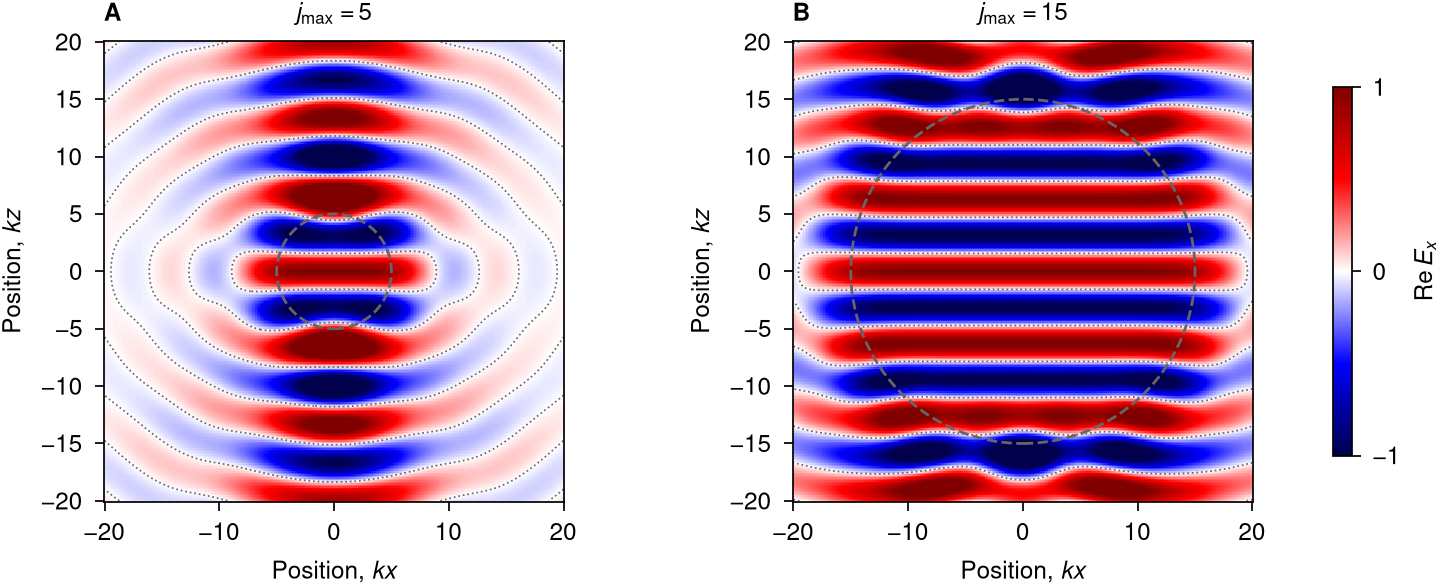

In [4]:
kx = np.linspace(-20, 20, 301)
kz = np.linspace(-20, 20, 301)
X, Z = np.meshgrid(kx, kz)
r, theta, phi = coordinates.cart2sph(X, 0, Z)


def plane_wave(jmax):
    """(x + iy) exp(ikz) from the harmonics with j <= jmax, in Cartesian components."""
    E = 0
    for j in range(1, jmax + 1):
        c = 1j**(j + 1) * np.sqrt(4 * np.pi * (2 * j + 1) / (j * (j + 1)))
        E = E + c * (vsh.M(j, 1, r, theta, phi, superscript=1) + vsh.N(j, 1, r, theta, phi, superscript=1))
    return coordinates.vector_sph2cart(E, theta, phi)


fig, axes = figure('double', cols=2)
for ax, jmax, name in zip(axes, [5, 15], 'AB'):
    Ex = plane_wave(jmax)[0].real
    mesh = signed_map(ax, kx, kz, Ex, vmax=1)
    ax.add_patch(plt.Circle((0, 0), jmax, fill=False, color='0.4', ls='--', lw=0.8))
    ax.set_aspect('equal')
    ax.set_title(rf'$j_{{\max}} = {jmax}$')
    ax.set_xlabel(r'Position, $kx$')
    ax.set_ylabel(r'Position, $kz$')
    letter(ax, name)

# the field fills both panels, so the colour bar is outside
bar = fig.colorbar(mesh, ax=axes, ticks=[-1, 0, 1], shrink=0.8, label=r'$\mathrm{Re}\, E_x$')
bar.outline.set_linewidth(0.5)
plt.show()